In [1]:
import nflreadpy as nfl

In [4]:
# Load current season play-by-play data
pbp = nfl.load_pbp()

# Load player game-level stats for multiple seasons
player_stats = nfl.load_player_stats([2022, 2023])

# Load all available team level stats
team_stats = nfl.load_team_stats(seasons=True)

# nflreadpy uses Polars instead of pandas. Convert to pandas if needed:
pbp_pandas = pbp.to_pandas()

In [ ]:
pbp_pandas.describe()

,play_id,week,yardline_100,quarter_seconds_remaining,half_seconds_remaining,game_seconds_remaining,quarter_end,drive,sp,qtr,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
count,48771.000000,48771.000000,45223.000000,48767.000000,48767.000000,48767.000000,48771.000000,48199.000000,48771.000000,48771.000000,...,48771.000000,48771.000000,48201.000000,16324.000000,16324.000000,16324.000000,16324.000000,16324.000000,37054.000000,36019.000000
mean,2182.106354,9.963995,47.139089,407.981976,799.746899,1697.440011,0.017859,11.064835,0.077444,2.574235,...,0.086199,0.550266,0.018635,0.728706,5.473338,3.659520,0.779662,0.584863,0.627238,-1.610125
std,1273.746393,5.617576,23.757689,282.997000,561.669309,1060.741912,0.132440,6.434649,0.267297,1.132769,...,0.280660,0.497472,1.249830,0.515886,2.558843,2.623505,0.253354,0.357044,0.242487,42.539063
min,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,0.000000,-12.658111,-0.503328,0.442673,0.000000,0.038900,0.010310,0.013008,-99.538189
25%,1088.000000,5.000000,30.000000,143.000000,269.000000,769.000000,0.000000,6.000000,0.000000,2.000000,...,0.000000,0.000000,-0.550641,0.325145,3.733560,2.000000,0.560618,0.243860,0.453993,-42.702256
50%,2160.000000,10.000000,48.000000,386.000000,778.000000,1800.000000,0.000000,11.000000,0.000000,3.000000,...,0.000000,1.000000,0.000000,0.610474,4.567729,3.000000,0.983911,0.480265,0.599415,3.681308
75%,3256.000000,15.000000,66.000000,653.000000,1283.000000,2586.000000,0.000000,16.000000,0.000000,4.000000,...,0.000000,1.000000,0.552668,0.993294,6.777379,5.000000,1.000000,0.999362,0.859955,32.961553
max,5519.000000,22.000000,99.000000,900.000000,1800.000000,3600.000000,1.000000,30.000000,1.000000,5.000000,...,1.000000,1.000000,7.967405,5.456678,21.217798,33.000000,1.000000,1.000000,0.996563,97.848164


In [8]:
import polars as pl

start_season = 1999
end_season = nfl.get_current_season()

for season in range(start_season, end_season + 1):
    print(f"Loading {season}...")

    pbp = nfl.load_pbp(season)

    pbp.write_parquet(f"data/pbp_{season}.parquet")

Loading 1999...
Loading 2000...
Loading 2001...
Loading 2002...
Loading 2003...
Loading 2004...
Loading 2005...
Loading 2006...
Loading 2007...
Loading 2008...
Loading 2009...
Loading 2010...
Loading 2011...
Loading 2012...
Loading 2013...
Loading 2014...
Loading 2015...
Loading 2016...
Loading 2017...
Loading 2018...
Loading 2019...
Loading 2020...
Loading 2021...
Loading 2022...
Loading 2023...
Loading 2024...
Loading 2025...


In [132]:
import pandas as pd

df = pd.read_parquet("data/")

In [133]:
expected = set(range(1999, 2026))
actual = set(df["season"].dropna().unique())

missing = expected - actual
present = actual

print("Present seasons:", sorted(present))
print("Missing seasons:", sorted(missing))
print("Total seasons:", len(present))

Present seasons: [1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Missing seasons: []
Total seasons: 27


In [134]:
df_fourth = df[df["down"] == 4]

df_fourth["play_type"].value_counts()

punt          66137
field_goal    25455
pass           9629
run            5886
no_play        5699
qb_kneel         83
Name: play_type, dtype: int64

In [135]:
df_fourth["label"] = df_fourth["play_type"].map({
    "run": "go",
    "pass": "go",
    "punt": "punt",
    "field_goal": "fg"
})

C:\Users\afzal\AppData\Local\Temp\ipykernel_27784\3073120474.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fourth["label"] = df_fourth["play_type"].map({


In [136]:
df_fourth["label"].value_counts()

punt    66137
fg      25455
go      15515
Name: label, dtype: int64

In [137]:
df_fourth["play_type"].isnull().sum()

267

In [138]:
plays_per_game = df_fourth.groupby("game_id").size()

avg_4th_down_per_game = plays_per_game.mean()

print(avg_4th_down_per_game)

15.558366561253953


In [139]:
len(df_fourth)

113156

In [140]:
df_fourth["down"].value_counts()

4.0    113156
Name: down, dtype: int64

In [141]:
df_fourth.columns.to_list()

['play_id',
 'game_id',
 'old_game_id',
 'home_team',
 'away_team',
 'season_type',
 'week',
 'posteam',
 'posteam_type',
 'defteam',
 'side_of_field',
 'yardline_100',
 'game_date',
 'quarter_seconds_remaining',
 'half_seconds_remaining',
 'game_seconds_remaining',
 'game_half',
 'quarter_end',
 'drive',
 'sp',
 'qtr',
 'down',
 'goal_to_go',
 'time',
 'yrdln',
 'ydstogo',
 'ydsnet',
 'desc',
 'play_type',
 'yards_gained',
 'shotgun',
 'no_huddle',
 'qb_dropback',
 'qb_kneel',
 'qb_spike',
 'qb_scramble',
 'pass_length',
 'pass_location',
 'air_yards',
 'yards_after_catch',
 'run_location',
 'run_gap',
 'field_goal_result',
 'kick_distance',
 'extra_point_result',
 'two_point_conv_result',
 'home_timeouts_remaining',
 'away_timeouts_remaining',
 'timeout',
 'timeout_team',
 'td_team',
 'td_player_name',
 'td_player_id',
 'posteam_timeouts_remaining',
 'defteam_timeouts_remaining',
 'total_home_score',
 'total_away_score',
 'posteam_score',
 'defteam_score',
 'score_differential',
 'po

In [142]:
df_fourth["posteam"].unique()

array(['PHI', 'ARI', 'BUF', 'IND', 'CAR', 'NO', 'CIN', 'TEN', 'WAS',
       'DAL', 'DET', 'SEA', 'KC', 'CHI', 'MIA', 'DEN', 'ATL', 'MIN', 'NE',
       'NYJ', 'NYG', 'TB', 'GB', 'LV', 'PIT', 'CLE', 'JAX', 'SF', 'BAL',
       'LAC', 'LA', 'HOU'], dtype=object)

In [143]:
df_fourth["week"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22])

In [144]:
df_fourth[df_fourth["season_type"] == "REG"]["week"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18])

In [145]:
df_fourth[df_fourth["season_type"] == "POST"]["week"].unique()

array([18, 19, 20, 21, 22])

In [146]:
features = [
    "game_id",
    "season",
    "home_team",
    "away_team",
    "posteam",
    "defteam",
    "qtr",
    "game_seconds_remaining",
    "yardline_100",
    "ydstogo",
    "goal_to_go",
    "score_differential",
    "home_score",
    "total_home_score",
    "away_score",
    "total_away_score",
    "wp",
    "def_wp",
    "spread_line",
    "total_line",
    "play_type",
    "posteam_type",
    "home_coach",
    "away_coach",
    "epa",
    "wpa",
    "success",
    "fourth_down_converted",
    "fourth_down_failed",
    "label",
    "week",
    "season_type"
]

In [147]:
df_fourth = df_fourth[features]

In [148]:
df_fourth.head()

,game_id,season,home_team,away_team,posteam,defteam,qtr,game_seconds_remaining,yardline_100,ydstogo,...,home_coach,away_coach,epa,wpa,success,fourth_down_converted,fourth_down_failed,label,week,season_type
5,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,1.0,3600.0,71.0,4.0,...,Andy Reid,Vince Tobin,1.027826,0.033497,1.0,0.0,0.0,punt,1,REG
9,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,1.0,3487.0,76.0,5.0,...,Andy Reid,Vince Tobin,0.068249,0.003924,1.0,0.0,0.0,punt,1,REG
24,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,1.0,3156.0,72.0,15.0,...,Andy Reid,Vince Tobin,0.416070,-0.006721,1.0,0.0,0.0,punt,1,REG
65,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,2.0,2700.0,13.0,5.0,...,Andy Reid,Vince Tobin,0.375625,-0.036044,1.0,0.0,0.0,fg,1,REG
73,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,2.0,2201.0,8.0,7.0,...,Andy Reid,Vince Tobin,0.200740,-0.030018,1.0,0.0,0.0,fg,1,REG


In [149]:
team_map = {
    "KAN": "KC",
    "RAI": "LV",
    "RAM": "LA",
    "SFO": "SF",
    "NWE": "NE",
    "CLT": "IND",
    "HTX": "HOU",
    "GNB": "GB",
    "NOR": "NO",
    "TAM": "TB",
    "SDG": "LAC",
    "OTI": "TEN",
    "CRD": "ARI",
    "RAV": "BAL"
}

In [150]:
weekly_standings = pd.read_csv("weekly_standings.csv")

In [151]:
weekly_standings.head()

,Year,Week,Team,Division,Wins,Losses,Ties,League Rank,Division Rank
0,1999,1,atl,NFC West,0,0,0,1,1
1,1999,1,buf,AFC East,0,0,0,2,1
2,1999,1,car,NFC West,0,0,0,3,2
3,1999,1,chi,NFC Central,0,0,0,4,1
4,1999,1,cin,AFC Central,0,0,0,5,1


In [152]:
weekly_standings["Team"].unique()

array(['atl', 'buf', 'car', 'chi', 'cin', 'cle', 'clt', 'crd', 'dal',
       'den', 'det', 'gnb', 'jax', 'kan', 'mia', 'min', 'nor', 'nwe',
       'nyg', 'nyj', 'oti', 'phi', 'pit', 'rai', 'ram', 'rav', 'sdg',
       'sea', 'sfo', 'tam', 'was', 'htx'], dtype=object)

In [153]:
weekly_standings["Team"] = weekly_standings["Team"].str.upper()

In [154]:
weekly_standings["Team"] = weekly_standings["Team"].replace(team_map)

In [155]:
df_fourth["posteam"].unique()

array(['PHI', 'ARI', 'BUF', 'IND', 'CAR', 'NO', 'CIN', 'TEN', 'WAS',
       'DAL', 'DET', 'SEA', 'KC', 'CHI', 'MIA', 'DEN', 'ATL', 'MIN', 'NE',
       'NYJ', 'NYG', 'TB', 'GB', 'LV', 'PIT', 'CLE', 'JAX', 'SF', 'BAL',
       'LAC', 'LA', 'HOU'], dtype=object)

In [156]:
weekly_standings["Team"].unique()

array(['ATL', 'BUF', 'CAR', 'CHI', 'CIN', 'CLE', 'IND', 'ARI', 'DAL',
       'DEN', 'DET', 'GB', 'JAX', 'KC', 'MIA', 'MIN', 'NO', 'NE', 'NYG',
       'NYJ', 'TEN', 'PHI', 'PIT', 'LV', 'LA', 'BAL', 'LAC', 'SEA', 'SF',
       'TB', 'WAS', 'HOU'], dtype=object)

In [157]:
weekly_standings["Year"].unique()

array([1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009,
       2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020,
       2021, 2022, 2023, 2024, 2025], dtype=int64)

In [158]:
weekly_standings["Week"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18], dtype=int64)

In [159]:
weekly_standings[weekly_standings["Week"] == 1][weekly_standings["Year"] == 2006]

C:\Users\afzal\AppData\Local\Temp\ipykernel_27784\1815252072.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  weekly_standings[weekly_standings["Week"] == 1][weekly_standings["Year"] == 2006]


,Year,Week,Team,Division,Wins,Losses,Ties,League Rank,Division Rank
3757,2006,1,ATL,NFC South,0,0,0,1,1
3758,2006,1,BUF,AFC East,0,0,0,2,1
3759,2006,1,CAR,NFC South,0,0,0,3,2
3760,2006,1,CHI,NFC North,0,0,0,4,1
3761,2006,1,CIN,AFC North,0,0,0,5,1
3762,2006,1,CLE,AFC North,0,0,0,6,2
3763,2006,1,IND,AFC South,0,0,0,7,1
3764,2006,1,ARI,NFC West,0,0,0,8,1
3765,2006,1,DAL,NFC East,0,0,0,9,1
3766,2006,1,DEN,AFC West,0,0,0,10,1


In [160]:
# OFFENSE (posteam)
df_fourth = df_fourth.merge(
    weekly_standings,
    left_on=["season", "week", "posteam"],
    right_on=["Year", "Week", "Team"],
    how="left"
).rename(columns={
    "Wins": "off_Wins_weekly",
    "Losses": "off_Losses_weekly",
    "Ties": "off_Ties_weekly",
    "League Rank": "off_League_Rank_weekly",
    "Division Rank": "off_Division_Rank_weekly",
    "Division": "off_Division_weekly"
}).drop(columns=["Year", "Week", "Team"])

# DEFENSE (defteam)
df_fourth = df_fourth.merge(
    weekly_standings,
    left_on=["season", "week", "defteam"],
    right_on=["Year", "Week", "Team"],
    how="left"
).rename(columns={
    "Wins": "def_Wins_weekly",
    "Losses": "def_Losses_weekly",
    "Ties": "def_Ties_weekly",
    "League Rank": "def_League_Rank_weekly",
    "Division Rank": "def_Division_Rank_weekly",
    "Division": "def_Division_weekly"
}).drop(columns=["Year", "Week", "Team"])

In [161]:
df_fourth[df_fourth["posteam"] == "PHI"][df_fourth["season"] == 1999]

C:\Users\afzal\AppData\Local\Temp\ipykernel_27784\181359370.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_fourth[df_fourth["posteam"] == "PHI"][df_fourth["season"] == 1999]


,game_id,season,home_team,away_team,posteam,defteam,qtr,game_seconds_remaining,yardline_100,ydstogo,...,off_Losses_weekly,off_Ties_weekly,off_League_Rank_weekly,off_Division_Rank_weekly,def_Division_weekly,def_Wins_weekly,def_Losses_weekly,def_Ties_weekly,def_League_Rank_weekly,def_Division_Rank_weekly
0,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,1.0,3600.0,71.0,4.0,...,0.0,0.0,22.0,4.0,NFC East,0.0,0.0,0.0,8.0,1.0
5,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,2.0,2115.0,58.0,9.0,...,0.0,0.0,22.0,4.0,NFC East,0.0,0.0,0.0,8.0,1.0
7,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,2.0,1867.0,66.0,6.0,...,0.0,0.0,22.0,4.0,NFC East,0.0,0.0,0.0,8.0,1.0
8,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,2.0,1804.0,8.0,8.0,...,0.0,0.0,22.0,4.0,NFC East,0.0,0.0,0.0,8.0,1.0
10,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,3.0,1442.0,40.0,2.0,...,0.0,0.0,22.0,4.0,NFC East,0.0,0.0,0.0,8.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4127,1999_17_STL_PHI,1999,PHI,LA,PHI,LA,2.0,1983.0,60.0,10.0,...,11.0,0.0,28.0,5.0,NFC West,13.0,2.0,0.0,3.0,1.0
4129,1999_17_STL_PHI,1999,PHI,LA,PHI,LA,3.0,1462.0,56.0,2.0,...,11.0,0.0,28.0,5.0,NFC West,13.0,2.0,0.0,3.0,1.0
4130,1999_17_STL_PHI,1999,PHI,LA,PHI,LA,4.0,382.0,69.0,11.0,...,11.0,0.0,28.0,5.0,NFC West,13.0,2.0,0.0,3.0,1.0
4131,1999_17_STL_PHI,1999,PHI,LA,PHI,LA,4.0,296.0,21.0,5.0,...,11.0,0.0,28.0,5.0,NFC West,13.0,2.0,0.0,3.0,1.0


In [162]:
weekly_standings[weekly_standings["Year"] == 1999][weekly_standings["Team"] == "PHI"]

C:\Users\afzal\AppData\Local\Temp\ipykernel_27784\1675190082.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  weekly_standings[weekly_standings["Year"] == 1999][weekly_standings["Team"] == "PHI"]


,Year,Week,Team,Division,Wins,Losses,Ties,League Rank,Division Rank
21,1999,1,PHI,NFC East,0,0,0,22,4
52,1999,2,PHI,NFC East,0,1,0,25,4
83,1999,3,PHI,NFC East,0,2,0,30,5
114,1999,4,PHI,NFC East,0,3,0,31,5
145,1999,5,PHI,NFC East,0,4,0,31,5
176,1999,6,PHI,NFC East,1,4,0,30,5
207,1999,7,PHI,NFC East,2,4,0,26,5
238,1999,8,PHI,NFC East,2,5,0,26,5
269,1999,9,PHI,NFC East,2,6,0,27,5
300,1999,10,PHI,NFC East,2,7,0,28,5


In [163]:
df_fourth["off_Wins_weekly"].notna().mean()

0.958411396655944

In [164]:
df_fourth.head()

,game_id,season,home_team,away_team,posteam,defteam,qtr,game_seconds_remaining,yardline_100,ydstogo,...,off_Losses_weekly,off_Ties_weekly,off_League_Rank_weekly,off_Division_Rank_weekly,def_Division_weekly,def_Wins_weekly,def_Losses_weekly,def_Ties_weekly,def_League_Rank_weekly,def_Division_Rank_weekly
0,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,1.0,3600.0,71.0,4.0,...,0.0,0.0,22.0,4.0,NFC East,0.0,0.0,0.0,8.0,1.0
1,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,1.0,3487.0,76.0,5.0,...,0.0,0.0,8.0,1.0,NFC East,0.0,0.0,0.0,22.0,4.0
2,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,1.0,3156.0,72.0,15.0,...,0.0,0.0,8.0,1.0,NFC East,0.0,0.0,0.0,22.0,4.0
3,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,2.0,2700.0,13.0,5.0,...,0.0,0.0,8.0,1.0,NFC East,0.0,0.0,0.0,22.0,4.0
4,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,2.0,2201.0,8.0,7.0,...,0.0,0.0,8.0,1.0,NFC East,0.0,0.0,0.0,22.0,4.0


In [165]:
df_fourth[df_fourth["week"] == 18][df_fourth["season"] == 2025]

C:\Users\afzal\AppData\Local\Temp\ipykernel_27784\3026985528.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_fourth[df_fourth["week"] == 18][df_fourth["season"] == 2025]


,game_id,season,home_team,away_team,posteam,defteam,qtr,game_seconds_remaining,yardline_100,ydstogo,...,off_Losses_weekly,off_Ties_weekly,off_League_Rank_weekly,off_Division_Rank_weekly,def_Division_weekly,def_Wins_weekly,def_Losses_weekly,def_Ties_weekly,def_League_Rank_weekly,def_Division_Rank_weekly
112701,2025_18_ARI_LA,2025,LA,ARI,LA,ARI,1.0,3371.0,16.0,3.0,...,5.0,0.0,10.0,3.0,NFC West,3.0,13.0,0.0,28.0,4.0
112702,2025_18_ARI_LA,2025,LA,ARI,ARI,LA,1.0,2910.0,27.0,18.0,...,13.0,0.0,28.0,4.0,NFC West,11.0,5.0,0.0,10.0,3.0
112703,2025_18_ARI_LA,2025,LA,ARI,LA,ARI,2.0,2509.0,23.0,13.0,...,5.0,0.0,10.0,3.0,NFC West,3.0,13.0,0.0,28.0,4.0
112704,2025_18_ARI_LA,2025,LA,ARI,ARI,LA,2.0,2380.0,38.0,16.0,...,13.0,0.0,28.0,4.0,NFC West,11.0,5.0,0.0,10.0,3.0
112705,2025_18_ARI_LA,2025,LA,ARI,LA,ARI,2.0,1886.0,2.0,2.0,...,5.0,0.0,10.0,3.0,NFC West,3.0,13.0,0.0,28.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112942,2025_18_WAS_PHI,2025,PHI,WAS,PHI,WAS,3.0,935.0,21.0,8.0,...,5.0,0.0,9.0,1.0,NFC East,4.0,12.0,0.0,27.0,3.0
112943,2025_18_WAS_PHI,2025,PHI,WAS,PHI,WAS,4.0,524.0,59.0,4.0,...,5.0,0.0,9.0,1.0,NFC East,4.0,12.0,0.0,27.0,3.0
112944,2025_18_WAS_PHI,2025,PHI,WAS,PHI,WAS,4.0,81.0,31.0,3.0,...,5.0,0.0,9.0,1.0,NFC East,4.0,12.0,0.0,27.0,3.0
112945,2025_18_WAS_PHI,2025,PHI,WAS,WAS,PHI,4.0,64.0,61.0,2.0,...,12.0,0.0,27.0,3.0,NFC East,11.0,5.0,0.0,9.0,1.0


In [166]:
df_fourth.columns.to_list()

['game_id',
 'season',
 'home_team',
 'away_team',
 'posteam',
 'defteam',
 'qtr',
 'game_seconds_remaining',
 'yardline_100',
 'ydstogo',
 'goal_to_go',
 'score_differential',
 'home_score',
 'total_home_score',
 'away_score',
 'total_away_score',
 'wp',
 'def_wp',
 'spread_line',
 'total_line',
 'play_type',
 'posteam_type',
 'home_coach',
 'away_coach',
 'epa',
 'wpa',
 'success',
 'fourth_down_converted',
 'fourth_down_failed',
 'label',
 'week',
 'season_type',
 'off_Division_weekly',
 'off_Wins_weekly',
 'off_Losses_weekly',
 'off_Ties_weekly',
 'off_League_Rank_weekly',
 'off_Division_Rank_weekly',
 'def_Division_weekly',
 'def_Wins_weekly',
 'def_Losses_weekly',
 'def_Ties_weekly',
 'def_League_Rank_weekly',
 'def_Division_Rank_weekly']

In [167]:
yearly_team_record_all = pd.read_csv("yearly_team_record_all.csv")

In [168]:
yearly_team_record_all.head()

,Year,Team,Wins,Losses,Ties,Division Placement,Division Name,Points For,Points For Per Game,Points For Ranking,Points Against,Points Against Per Game,Points Against Ranking,Expected Wins,Expected Losses,SRS,SRS Rank,SOS,SRS Rating,SOS Rating
0,1999,atl,5,11,0,3,NFC West,285,17.8,23,380,23.8,25,5.4,10.6,NaN,26,NaN,-7.07,-1.13
1,1999,buf,11,5,0,2,AFC East,320,20.0,16,229,14.3,2,11.0,5.0,NaN,2,NaN,7.14,1.45
2,1999,car,8,8,0,2,NFC West,421,26.3,4,381,23.8,26,8.9,7.1,NaN,21,NaN,-1.05,-3.55
3,1999,chi,6,10,0,5,NFC Central,272,17.0,25,341,21.3,20,5.9,10.1,NaN,22,NaN,-2.03,2.28
4,1999,cin,4,12,0,5,AFC Central,283,17.7,24,460,28.8,31,3.8,12.2,NaN,29,NaN,-11.51,-0.45


In [169]:
yearly_team_record_all["Team"].unique()

array(['atl', 'buf', 'car', 'chi', 'cin', 'cle', 'clt', 'crd', 'dal',
       'den', 'det', 'gnb', 'jax', 'kan', 'mia', 'min', 'nor', 'nwe',
       'nyg', 'nyj', 'oti', 'phi', 'pit', 'rai', 'ram', 'rav', 'sdg',
       'sea', 'sfo', 'tam', 'was', 'htx'], dtype=object)

In [170]:
yearly_team_record_all["Year"].unique()

array([1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009,
       2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020,
       2021, 2022, 2023, 2024, 2025], dtype=int64)

In [171]:
yearly_team_record_all["Team"] = yearly_team_record_all["Team"].str.upper()

In [172]:
yearly_team_record_all["Team"] = yearly_team_record_all["Team"].replace(team_map)

In [173]:
yearly_team_record_all["Team"].unique()

array(['ATL', 'BUF', 'CAR', 'CHI', 'CIN', 'CLE', 'IND', 'ARI', 'DAL',
       'DEN', 'DET', 'GB', 'JAX', 'KC', 'MIA', 'MIN', 'NO', 'NE', 'NYG',
       'NYJ', 'TEN', 'PHI', 'PIT', 'LV', 'LA', 'BAL', 'LAC', 'SEA', 'SF',
       'TB', 'WAS', 'HOU'], dtype=object)

In [174]:
yearly_team_record_all[yearly_team_record_all["Team"] == "DAL"]

,Year,Team,Wins,Losses,Ties,Division Placement,Division Name,Points For,Points For Per Game,Points For Ranking,Points Against,Points Against Per Game,Points Against Ranking,Expected Wins,Expected Losses,SRS,SRS Rank,SOS,SRS Rating,SOS Rating
8,1999,DAL,8,8,0,2,NFC East,352,22.0,11,276,17.3,5,10.2,5.8,NaN,10,NaN,3.12,-1.64
39,2000,DAL,5,11,0,4,NFC East,294,18.4,23,361,22.6,22,6.1,9.9,NaN,25,NaN,-4.58,-0.39
70,2001,DAL,5,11,0,5,NFC East,246,15.4,30,338,21.1,20,5.1,10.9,NaN,28,NaN,-5.99,-0.24
101,2002,DAL,5,11,0,4,NFC East,217,13.6,31,329,20.6,13,4.3,11.7,NaN,28,NaN,-8.48,-1.48
133,2003,DAL,10,6,0,2,NFC East,289,18.1,21,260,16.3,2,9.0,7.0,NaN,16,NaN,-0.46,-2.27
165,2004,DAL,6,10,0,3,NFC East,293,18.3,25,405,25.3,27,5.1,10.9,NaN,30,NaN,-7.77,-0.77
197,2005,DAL,9,7,0,3,NFC East,325,20.3,15,308,19.3,12,8.5,7.5,NaN,12,NaN,3.16,2.09
229,2006,DAL,9,7,0,2,NFC East,425,26.6,4,350,21.9,20,9.8,6.2,NaN,9,NaN,3.66,-1.03
261,2007,DAL,13,3,0,1,NFC East,455,28.4,2,325,20.3,13,11.0,5.0,NaN,3,NaN,9.47,1.35
293,2008,DAL,9,7,0,3,NFC East,362,22.6,18,365,22.8,20,7.9,8.1,NaN,16,NaN,0.57,0.75


In [175]:
yearly_team_record_all.columns.to_list()

['Year',
 'Team',
 'Wins',
 'Losses',
 'Ties',
 'Division Placement',
 'Division Name',
 'Points For',
 'Points For Per Game',
 'Points For Ranking',
 'Points Against',
 'Points Against Per Game',
 'Points Against Ranking',
 'Expected Wins',
 'Expected Losses',
 'SRS',
 'SRS Rank',
 'SOS',
 'SRS Rating',
 'SOS Rating']

In [176]:
yearly_off = yearly_team_record_all.add_prefix("off_yr_")
yearly_def = yearly_team_record_all.add_prefix("def_yr_")

In [177]:
off_yearly = yearly_team_record_all.rename(columns={
    "Wins": "off_Wins_yearly",
    "Losses": "off_Losses_yearly",
    "Ties": "off_Ties_yearly",
    "Division Placement": "off_Division_Placement_yearly",
    "Division Name": "off_Division_Name_yearly",
    "Points For": "off_Points_For_yearly",
    "Points For Per Game": "off_Points_For_Per_Game_yearly",
    "Points For Ranking": "off_Points_For_Ranking_yearly",
    "Points Against": "off_Points_Against_yearly",
    "Points Against Per Game": "off_Points_Against_Per_Game_yearly",
    "Points Against Ranking": "off_Points_Against_Ranking_yearly",
    "Expected Wins": "off_Expected_Wins_yearly",
    "Expected Losses": "off_Expected_Losses_yearly",
    "SRS": "off_SRS_yearly",
    "SRS Rank": "off_SRS_Rank_yearly",
    "SOS": "off_SOS_yearly",
    "SRS Rating": "off_SRS_Rating_yearly",
    "SOS Rating": "off_SOS_Rating_yearly"
})

df_fourth = df_fourth.merge(
    off_yearly,
    left_on=["season", "posteam"],
    right_on=["Year", "Team"],
    how="left"
).drop(columns=["Year", "Team"])


def_yearly = yearly_team_record_all.rename(columns={
    "Wins": "def_Wins_yearly",
    "Losses": "def_Losses_yearly",
    "Ties": "def_Ties_yearly",
    "Division Placement": "def_Division_Placement_yearly",
    "Division Name": "def_Division_Name_yearly",
    "Points For": "def_Points_For_yearly",
    "Points For Per Game": "def_Points_For_Per_Game_yearly",
    "Points For Ranking": "def_Points_For_Ranking_yearly",
    "Points Against": "def_Points_Against_yearly",
    "Points Against Per Game": "def_Points_Against_Per_Game_yearly",
    "Points Against Ranking": "def_Points_Against_Ranking_yearly",
    "Expected Wins": "def_Expected_Wins_yearly",
    "Expected Losses": "def_Expected_Losses_yearly",
    "SRS": "def_SRS_yearly",
    "SRS Rank": "def_SRS_Rank_yearly",
    "SOS": "def_SOS_yearly",
    "SRS Rating": "def_SRS_Rating_yearly",
    "SOS Rating": "def_SOS_Rating_yearly"
})

df_fourth = df_fourth.merge(
    def_yearly,
    left_on=["season", "defteam"],
    right_on=["Year", "Team"],
    how="left"
).drop(columns=["Year", "Team"])


In [178]:
df_fourth.head()

,game_id,season,home_team,away_team,posteam,defteam,qtr,game_seconds_remaining,yardline_100,ydstogo,...,def_Points_Against_yearly,def_Points_Against_Per_Game_yearly,def_Points_Against_Ranking_yearly,def_Expected_Wins_yearly,def_Expected_Losses_yearly,def_SRS_yearly,def_SRS_Rank_yearly,def_SOS_yearly,def_SRS_Rating_yearly,def_SOS_Rating_yearly
0,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,1.0,3600.0,71.0,4.0,...,382,23.9,27,4.1,11.9,NaN,27,NaN,-8.75,-0.19
1,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,1.0,3487.0,76.0,5.0,...,357,22.3,22,5.5,10.5,NaN,25,NaN,-4.23,1.08
2,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,1.0,3156.0,72.0,15.0,...,357,22.3,22,5.5,10.5,NaN,25,NaN,-4.23,1.08
3,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,2.0,2700.0,13.0,5.0,...,357,22.3,22,5.5,10.5,NaN,25,NaN,-4.23,1.08
4,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,2.0,2201.0,8.0,7.0,...,357,22.3,22,5.5,10.5,NaN,25,NaN,-4.23,1.08


In [179]:
df_fourth.columns.to_list()

['game_id',
 'season',
 'home_team',
 'away_team',
 'posteam',
 'defteam',
 'qtr',
 'game_seconds_remaining',
 'yardline_100',
 'ydstogo',
 'goal_to_go',
 'score_differential',
 'home_score',
 'total_home_score',
 'away_score',
 'total_away_score',
 'wp',
 'def_wp',
 'spread_line',
 'total_line',
 'play_type',
 'posteam_type',
 'home_coach',
 'away_coach',
 'epa',
 'wpa',
 'success',
 'fourth_down_converted',
 'fourth_down_failed',
 'label',
 'week',
 'season_type',
 'off_Division_weekly',
 'off_Wins_weekly',
 'off_Losses_weekly',
 'off_Ties_weekly',
 'off_League_Rank_weekly',
 'off_Division_Rank_weekly',
 'def_Division_weekly',
 'def_Wins_weekly',
 'def_Losses_weekly',
 'def_Ties_weekly',
 'def_League_Rank_weekly',
 'def_Division_Rank_weekly',
 'off_Wins_yearly',
 'off_Losses_yearly',
 'off_Ties_yearly',
 'off_Division_Placement_yearly',
 'off_Division_Name_yearly',
 'off_Points_For_yearly',
 'off_Points_For_Per_Game_yearly',
 'off_Points_For_Ranking_yearly',
 'off_Points_Against_year

In [180]:
df_fourth.head()

,game_id,season,home_team,away_team,posteam,defteam,qtr,game_seconds_remaining,yardline_100,ydstogo,...,def_Points_Against_yearly,def_Points_Against_Per_Game_yearly,def_Points_Against_Ranking_yearly,def_Expected_Wins_yearly,def_Expected_Losses_yearly,def_SRS_yearly,def_SRS_Rank_yearly,def_SOS_yearly,def_SRS_Rating_yearly,def_SOS_Rating_yearly
0,1999_01_ARI_PHI,1999,PHI,ARI,PHI,ARI,1.0,3600.0,71.0,4.0,...,382,23.9,27,4.1,11.9,NaN,27,NaN,-8.75,-0.19
1,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,1.0,3487.0,76.0,5.0,...,357,22.3,22,5.5,10.5,NaN,25,NaN,-4.23,1.08
2,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,1.0,3156.0,72.0,15.0,...,357,22.3,22,5.5,10.5,NaN,25,NaN,-4.23,1.08
3,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,2.0,2700.0,13.0,5.0,...,357,22.3,22,5.5,10.5,NaN,25,NaN,-4.23,1.08
4,1999_01_ARI_PHI,1999,PHI,ARI,ARI,PHI,2.0,2201.0,8.0,7.0,...,357,22.3,22,5.5,10.5,NaN,25,NaN,-4.23,1.08


In [190]:
df_fourth[["season","posteam","off_League_Rank_weekly"]].head()

,season,posteam,off_League_Rank_weekly
0,1999,PHI,22.0
1,1999,ARI,8.0
2,1999,ARI,8.0
3,1999,ARI,8.0
4,1999,ARI,8.0


In [191]:
weekly_standings[
    (weekly_standings.Year == 1999) &
    (weekly_standings.Week == 1) &
    (weekly_standings.Team == "ARI")
]

,Year,Week,Team,Division,Wins,Losses,Ties,League Rank,Division Rank
7,1999,1,ARI,NFC East,0,0,0,8,1


In [192]:
from datasets import Dataset

hf_dataset = Dataset.from_pandas(df_fourth)

In [193]:
print(hf_dataset)
print(hf_dataset[0])

Dataset({
    features: ['game_id', 'season', 'home_team', 'away_team', 'posteam', 'defteam', 'qtr', 'game_seconds_remaining', 'yardline_100', 'ydstogo', 'goal_to_go', 'score_differential', 'home_score', 'total_home_score', 'away_score', 'total_away_score', 'wp', 'def_wp', 'spread_line', 'total_line', 'play_type', 'posteam_type', 'home_coach', 'away_coach', 'epa', 'wpa', 'success', 'fourth_down_converted', 'fourth_down_failed', 'label', 'week', 'season_type', 'off_Division_weekly', 'off_Wins_weekly', 'off_Losses_weekly', 'off_Ties_weekly', 'off_League_Rank_weekly', 'off_Division_Rank_weekly', 'def_Division_weekly', 'def_Wins_weekly', 'def_Losses_weekly', 'def_Ties_weekly', 'def_League_Rank_weekly', 'def_Division_Rank_weekly', 'off_Wins_yearly', 'off_Losses_yearly', 'off_Ties_yearly', 'off_Division_Placement_yearly', 'off_Division_Name_yearly', 'off_Points_For_yearly', 'off_Points_For_Per_Game_yearly', 'off_Points_For_Ranking_yearly', 'off_Points_Against_yearly', 'off_Points_Against_Per

In [194]:
hf_dataset.save_to_disk("fourth_down_dataset")

Saving the dataset (0/1 shards):   0%|          | 0/113156 [00:00<?, ? examples/s]

In [195]:
print(hf_dataset)
print(hf_dataset.features)
print(hf_dataset[0])

Dataset({
    features: ['game_id', 'season', 'home_team', 'away_team', 'posteam', 'defteam', 'qtr', 'game_seconds_remaining', 'yardline_100', 'ydstogo', 'goal_to_go', 'score_differential', 'home_score', 'total_home_score', 'away_score', 'total_away_score', 'wp', 'def_wp', 'spread_line', 'total_line', 'play_type', 'posteam_type', 'home_coach', 'away_coach', 'epa', 'wpa', 'success', 'fourth_down_converted', 'fourth_down_failed', 'label', 'week', 'season_type', 'off_Division_weekly', 'off_Wins_weekly', 'off_Losses_weekly', 'off_Ties_weekly', 'off_League_Rank_weekly', 'off_Division_Rank_weekly', 'def_Division_weekly', 'def_Wins_weekly', 'def_Losses_weekly', 'def_Ties_weekly', 'def_League_Rank_weekly', 'def_Division_Rank_weekly', 'off_Wins_yearly', 'off_Losses_yearly', 'off_Ties_yearly', 'off_Division_Placement_yearly', 'off_Division_Name_yearly', 'off_Points_For_yearly', 'off_Points_For_Per_Game_yearly', 'off_Points_For_Ranking_yearly', 'off_Points_Against_yearly', 'off_Points_Against_Per

In [196]:
print(hf_dataset.column_names)

['game_id', 'season', 'home_team', 'away_team', 'posteam', 'defteam', 'qtr', 'game_seconds_remaining', 'yardline_100', 'ydstogo', 'goal_to_go', 'score_differential', 'home_score', 'total_home_score', 'away_score', 'total_away_score', 'wp', 'def_wp', 'spread_line', 'total_line', 'play_type', 'posteam_type', 'home_coach', 'away_coach', 'epa', 'wpa', 'success', 'fourth_down_converted', 'fourth_down_failed', 'label', 'week', 'season_type', 'off_Division_weekly', 'off_Wins_weekly', 'off_Losses_weekly', 'off_Ties_weekly', 'off_League_Rank_weekly', 'off_Division_Rank_weekly', 'def_Division_weekly', 'def_Wins_weekly', 'def_Losses_weekly', 'def_Ties_weekly', 'def_League_Rank_weekly', 'def_Division_Rank_weekly', 'off_Wins_yearly', 'off_Losses_yearly', 'off_Ties_yearly', 'off_Division_Placement_yearly', 'off_Division_Name_yearly', 'off_Points_For_yearly', 'off_Points_For_Per_Game_yearly', 'off_Points_For_Ranking_yearly', 'off_Points_Against_yearly', 'off_Points_Against_Per_Game_yearly', 'off_Poin

In [197]:
import numpy as np

def missing_stats(ds):
    stats = {}
    for col in ds.column_names:
        values = ds[col]
        # count None / NaN safely
        missing = sum(
            v is None or (isinstance(v, float) and np.isnan(v))
            for v in values
        )
        stats[col] = missing / len(ds)
    return stats

print(missing_stats(hf_dataset))

{'game_id': 0.0, 'season': 0.0, 'home_team': 0.0, 'away_team': 0.0, 'posteam': 0.0, 'defteam': 0.0, 'qtr': 0.0, 'game_seconds_remaining': 0.0, 'yardline_100': 0.0, 'ydstogo': 0.0, 'goal_to_go': 0.0, 'score_differential': 0.0, 'home_score': 0.0, 'total_home_score': 0.0, 'away_score': 0.0, 'total_away_score': 0.0, 'wp': 8.837357276679982e-06, 'def_wp': 8.837357276679982e-06, 'spread_line': 0.0, 'total_line': 0.0, 'play_type': 0.002359574392873555, 'posteam_type': 0.0, 'home_coach': 0.0, 'away_coach': 0.0, 'epa': 8.837357276679982e-06, 'wpa': 0.0007511753685177984, 'success': 8.837357276679982e-06, 'fourth_down_converted': 0.003702852698928912, 'fourth_down_failed': 0.003702852698928912, 'label': 0.05345717416663721, 'week': 0.0, 'season_type': 0.0, 'off_Division_weekly': 0.041588603344055994, 'off_Wins_weekly': 0.041588603344055994, 'off_Losses_weekly': 0.041588603344055994, 'off_Ties_weekly': 0.041588603344055994, 'off_League_Rank_weekly': 0.041588603344055994, 'off_Division_Rank_weekly

In [198]:
from collections import Counter

print(Counter(hf_dataset["play_type"]))

Counter({'punt': 66137, 'field_goal': 25455, 'pass': 9629, 'run': 5886, 'no_play': 5699, None: 267, 'qb_kneel': 83})


In [199]:
print(Counter(hf_dataset["label"]))

Counter({'punt': 66137, 'fg': 25455, 'go': 15515, None: 6049})


In [200]:
import numpy as np

yardline = np.array(hf_dataset["yardline_100"])
ydstogo = np.array(hf_dataset["ydstogo"])

print("yardline min/max:", np.nanmin(yardline), np.nanmax(yardline))
print("ydstogo min/max:", np.nanmin(ydstogo), np.nanmax(ydstogo))

yardline min/max: 1.0 99.0
ydstogo min/max: 1.0 48.0


In [201]:
leak_cols = [
    "epa", "wpa", "yards_gained", "success",
    "touchdown", "drive_ended_with_score"
]

print([c for c in hf_dataset.column_names if c in leak_cols])

['epa', 'wpa', 'success']


In [202]:
print({
    "rows": len(hf_dataset),
    "cols": len(hf_dataset.column_names),
    "unique_games": len(set(hf_dataset["game_id"]))
})

{'rows': 113156, 'cols': 81, 'unique_games': 7273}


In [42]:
from huggingface_hub import login

login()

In [203]:
hf_dataset.info.description = "NFL 4th down play-by-play dataset for decision modeling (go/punt/field goal)"

In [204]:
hf_dataset

Dataset({
    features: ['game_id', 'season', 'home_team', 'away_team', 'posteam', 'defteam', 'qtr', 'game_seconds_remaining', 'yardline_100', 'ydstogo', 'goal_to_go', 'score_differential', 'home_score', 'total_home_score', 'away_score', 'total_away_score', 'wp', 'def_wp', 'spread_line', 'total_line', 'play_type', 'posteam_type', 'home_coach', 'away_coach', 'epa', 'wpa', 'success', 'fourth_down_converted', 'fourth_down_failed', 'label', 'week', 'season_type', 'off_Division_weekly', 'off_Wins_weekly', 'off_Losses_weekly', 'off_Ties_weekly', 'off_League_Rank_weekly', 'off_Division_Rank_weekly', 'def_Division_weekly', 'def_Wins_weekly', 'def_Losses_weekly', 'def_Ties_weekly', 'def_League_Rank_weekly', 'def_Division_Rank_weekly', 'off_Wins_yearly', 'off_Losses_yearly', 'off_Ties_yearly', 'off_Division_Placement_yearly', 'off_Division_Name_yearly', 'off_Points_For_yearly', 'off_Points_For_Per_Game_yearly', 'off_Points_For_Ranking_yearly', 'off_Points_Against_yearly', 'off_Points_Against_Per

In [205]:
hf_dataset.push_to_hub("afzalmengal/nfl-4th-downs-dataset")

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Creating parquet from Arrow format:   0%|          | 0/114 [00:00<?, ?ba/s]

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


CommitInfo(commit_url='https://huggingface.co/datasets/afzalmengal/nfl-4th-downs-dataset/commit/21d27783e33594a8f9190985c0a3c90eb1ae72e2', commit_message='Upload dataset', commit_description='', oid='21d27783e33594a8f9190985c0a3c90eb1ae72e2', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/afzalmengal/nfl-4th-downs-dataset', endpoint='https://huggingface.co', repo_type='dataset', repo_id='afzalmengal/nfl-4th-downs-dataset'), pr_revision=None, pr_num=None)

In [206]:
from datasets import load_dataset

ds = load_dataset("afzalmengal/nfl-4th-downs-dataset")

README.md: 0.00B [00:00, ?B/s]

c:\Users\afzal\miniconda3\envs\torch\lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\afzal\.cache\huggingface\hub\datasets--afzalmengal--nfl-4th-downs-dataset. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


train-00000-of-00001.parquet:   0%|          | 0.00/10.6M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/113156 [00:00<?, ? examples/s]

In [207]:
ds["train"][0]

{'game_id': '1999_01_ARI_PHI',
 'season': 1999,
 'home_team': 'PHI',
 'away_team': 'ARI',
 'posteam': 'PHI',
 'defteam': 'ARI',
 'qtr': 1.0,
 'game_seconds_remaining': 3600.0,
 'yardline_100': 71.0,
 'ydstogo': 4.0,
 'goal_to_go': 0.0,
 'score_differential': 0.0,
 'home_score': 24,
 'total_home_score': 0.0,
 'away_score': 25,
 'total_away_score': 0.0,
 'wp': 0.4842130243778229,
 'def_wp': 0.5157869756221771,
 'spread_line': -3.0,
 'total_line': 37.0,
 'play_type': 'punt',
 'posteam_type': 'home',
 'home_coach': 'Andy Reid',
 'away_coach': 'Vince Tobin',
 'epa': 1.027826048899442,
 'wpa': 0.033496707677841187,
 'success': 1.0,
 'fourth_down_converted': 0.0,
 'fourth_down_failed': 0.0,
 'label': 'punt',
 'week': 1,
 'season_type': 'REG',
 'off_Division_weekly': 'NFC East',
 'off_Wins_weekly': 0.0,
 'off_Losses_weekly': 0.0,
 'off_Ties_weekly': 0.0,
 'off_League_Rank_weekly': 22.0,
 'off_Division_Rank_weekly': 4.0,
 'def_Division_weekly': 'NFC East',
 'def_Wins_weekly': 0.0,
 'def_Losses_

In [208]:
ds

DatasetDict({
    train: Dataset({
        features: ['game_id', 'season', 'home_team', 'away_team', 'posteam', 'defteam', 'qtr', 'game_seconds_remaining', 'yardline_100', 'ydstogo', 'goal_to_go', 'score_differential', 'home_score', 'total_home_score', 'away_score', 'total_away_score', 'wp', 'def_wp', 'spread_line', 'total_line', 'play_type', 'posteam_type', 'home_coach', 'away_coach', 'epa', 'wpa', 'success', 'fourth_down_converted', 'fourth_down_failed', 'label', 'week', 'season_type', 'off_Division_weekly', 'off_Wins_weekly', 'off_Losses_weekly', 'off_Ties_weekly', 'off_League_Rank_weekly', 'off_Division_Rank_weekly', 'def_Division_weekly', 'def_Wins_weekly', 'def_Losses_weekly', 'def_Ties_weekly', 'def_League_Rank_weekly', 'def_Division_Rank_weekly', 'off_Wins_yearly', 'off_Losses_yearly', 'off_Ties_yearly', 'off_Division_Placement_yearly', 'off_Division_Name_yearly', 'off_Points_For_yearly', 'off_Points_For_Per_Game_yearly', 'off_Points_For_Ranking_yearly', 'off_Points_Against_yea

In [209]:
total_4th = len(df_fourth)
total_games = df_fourth["game_id"].nunique()
total_seasons = df_fourth["season"].nunique()

print(total_4th, total_games, total_seasons)

113156 7273 27


In [210]:
class_counts = df_fourth["label"].value_counts()
class_pct = df_fourth["label"].value_counts(normalize=True) * 100

print(class_counts)
print(class_pct)

punt    66137
fg      25455
go      15515
Name: label, dtype: int64
punt    61.748532
fg      23.765954
go      14.485514
Name: label, dtype: float64


In [211]:
class_counts = df_fourth["play_type"].value_counts()
class_pct = df_fourth["play_type"].value_counts(normalize=True) * 100

print(class_counts)
print(class_pct)

punt          66137
field_goal    25455
pass           9629
run            5886
no_play        5699
qb_kneel         83
Name: play_type, dtype: int64
punt          58.585868
field_goal    22.548698
pass           8.529618
run            5.213971
no_play        5.048322
qb_kneel       0.073524
Name: play_type, dtype: float64


In [212]:
plays_per_game = df_fourth.groupby("game_id").size()

avg_4th_per_game = plays_per_game.mean()
print(avg_4th_per_game)

15.558366561253953


In [213]:
games_per_season = df_fourth.groupby("season")["game_id"].nunique()

avg_games_per_season = games_per_season.mean()
print(avg_games_per_season)

269.3703703703704


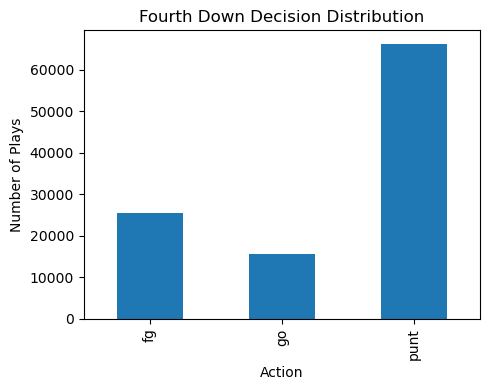

In [ ]:
from datasets import load_dataset
import matplotlib.pyplot as plt

# Load dataset
ds = load_dataset("afzalmengal/nfl-4th-downs-dataset", split="train")  # replace with your dataset

# Convert to pandas
df = ds.to_pandas()

# Count plays
counts = df["label"].value_counts().sort_index()

# Plot
plt.figure(figsize=(5, 4))
counts.plot(kind="bar")

plt.xlabel("Action")
plt.ylabel("Number of Plays")
plt.title("Fourth Down Decision Distribution")

plt.tight_layout()
plt.show()

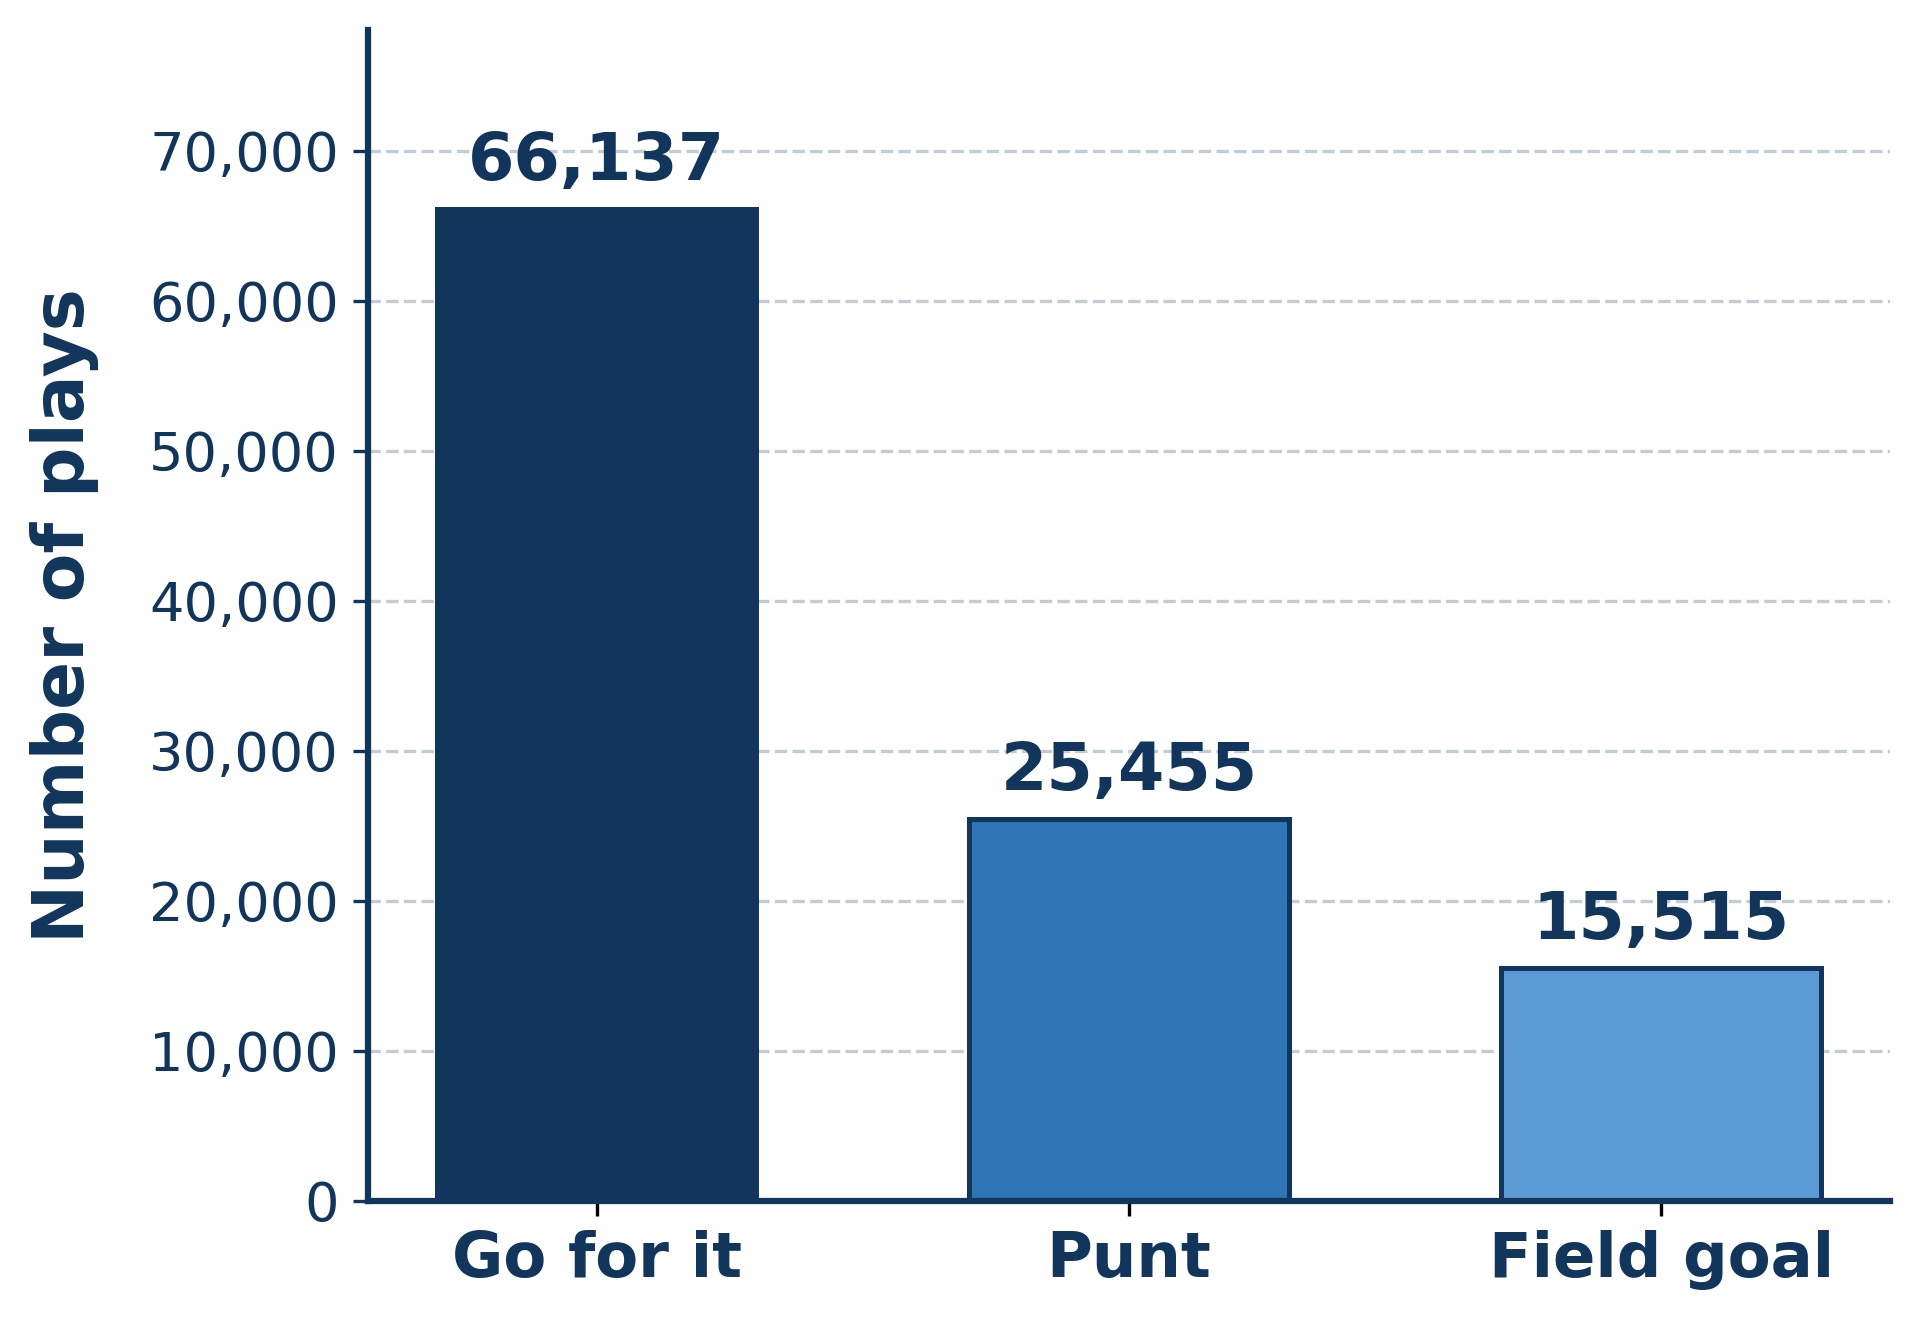

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Counts
counts = df["label"].value_counts()

# Dark blue theme
dark_blue = "#12355B"
light_blue = "#2E75B6"

colors = [dark_blue, light_blue, "#5B9BD5"]

fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=300)

bars = ax.bar(
    counts.index,
    counts.values,
    color=colors,
    width=0.6,
    edgecolor=dark_blue,
    linewidth=1.2,
)

# Annotate bars
for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        h + counts.max()*0.015,
        f"{h:,}",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
        color=dark_blue,
    )

# Labels
ax.set_ylabel(
    "Number of plays",
    fontsize=17,
    fontweight="bold",
    color=dark_blue,
    labelpad=12,
)

ax.set_xticks(range(len(counts.index)))
ax.set_xticklabels(
    ["Go for it", "Punt", "Field goal"],
    fontsize=15,
    fontweight="bold",
    color=dark_blue,
)

ax.tick_params(
    axis="y",
    labelsize=13,
    colors=dark_blue,
)

# Clean poster style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color(dark_blue)
ax.spines["bottom"].set_color(dark_blue)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.25,
    color=dark_blue,
)

ax.set_axisbelow(True)

# Extra room for labels
ax.set_ylim(0, counts.max() * 1.18)

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

plt.tight_layout()

plt.savefig(
    "decision_distribution_dark_blue.pdf",
    bbox_inches="tight",
    transparent=False,
    facecolor="white",
)

plt.show()